# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")
print(brut.shape)
print(brut.dtypes)
print(brut.isna().sum())
print(brut.duplicated().sum())

(300, 4)
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print(brut["quartier"].nunique())
print(brut["quartier"].value_counts())

43
quartier
Bois-Verna             24
Petite-Anse            24
Morne Calvaire         23
Delmas 33              22
Delmas 65              22
Carénage               22
Rue 15                 22
Delmas 75              21
Centre-ville           20
Thomassin              20
Place Saint-Pierre     20
Bas-Peu-de-Chose       18
BOIS-VERNA              4
 Morne Calvaire         3
bas-peu-de-chose        2
Bas-Peu-de-Chose        2
centre-ville            2
delmas 65               2
delmas 75               2
Thomassin               2
 Bas-Peu-de-Chose       1
BAS-PEU-DE-CHOSE        1
Centre-ville            1
CENTRE-VILLE            1
Delmas 33               1
 Delmas 33              1
DELMAS 33               1
 Delmas 65              1
Delmas 75               1
 Delmas 75              1
 Thomassin              1
THOMASSIN               1
PLACE SAINT-PIERRE      1
Place Saint-Pierre      1
place saint-pierre      1
 Place Saint-Pierre     1
Carénage                1
CARÉNAGE                1


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")
nonb = pd.to_numeric(brut["kwh"], errors="coerce")
problemes = brut[nonb.isna() & brut["kwh"].notna()]
print(len(problemes))
print(problemes["kwh"].head(15))

52
0     184410 kWh
4     206280 kWh
9     215140 kWh
13       251 900
21    274520 kWh
27    301740 kWh
36    233010 kWh
43    155930 kWh
51    212510 kWh
53    424110 kWh
55    299610 kWh
58       373 880
59    333670 kWh
62    597730 kWh
66    456060 kWh
Name: kwh, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = pd.to_numeric(
    propre["kwh"].str.replace(r"[^\d.]", "", regex=True)
)
print(propre["kwh"].isna().sum())

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")
noms = {q.lower(): q for q in quartiers["quartier"]}
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms)
print(propre["quartier"].isna().sum())
print(propre["quartier"].nunique())

0
12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates().dropna(subset=["kwh"]).reset_index(drop=True)
print(propre.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
med = propre.groupby("quartier")["kwh"].transform("median")
twop_gwo = propre["kwh"] > 3 * med
print(propre[twop_gwo])
propre.loc[twop_gwo, "kwh"] = propre.loc[twop_gwo, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)
print(propre["kwh"].max())

        mois        quartier        kwh  heures_courant
82   2025-02       Delmas 33  3602600.0            10.1
127  2025-02       Delmas 75  2012700.0            11.1
187  2024-02  Morne Calvaire  1439200.0            11.4
232  2024-01          Rue 15   997700.0             5.9
742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv("donnees/consommation.csv")
cles_valides = propre[["mois", "quartier"]]
reference = reference.merge(cles_valides, on=["mois", "quartier"], how="inner", validate="one_to_one")
colonnes = propre.columns
propre = propre.sort_values(["mois", "quartier"]).reset_index(drop=True)
reference = reference[colonnes].sort_values(["mois", "quartier"]).reset_index(drop=True)
print("Forme comparée :", propre.shape, reference.shape)
print("Identique au fichier de référence :", propre.equals(reference))
assert propre.equals(reference), "Le nettoyage diffère du fichier de référence."

Forme comparée : (279, 4) (279, 4)
Identique au fichier de référence : True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
n = len(propre)
avec_quartiers = propre.merge(quartiers, on="quartier", how="left")
print(n, len(avec_quartiers))

avec_quartiers["kwh_par_abonne"] = (
    avec_quartiers["kwh"] / avec_quartiers["abonnes"]
).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

print(avec_quartiers.query(
    "quartier == 'Bas-Peu-de-Chose' and mois == '2024-01'"
)["kwh_par_abonne"])

279

 279
0    85.8
Name: kwh_par_abonne, dtype: float64


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
print(len(avec_quartiers), len(avec_meteo))
print(avec_meteo["temperature_c"].isna().sum())

279 279
0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)
print(pd.read_csv("donnees/consommation_propre.csv").shape)

(279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
par_type = avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)
print(par_type)

classement = (
    avec_meteo.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)
print(classement)

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

Quartiers commerciaux consomment en moyenne 393.2 kWh par abonné, soit plus de 3 fois les quartiers résidentiels (117.4). 
Centre-ville (468.7), 
Place Saint-Pierre (458.3) et Delmas 33 (374.4) arrivent en tête, 
Tandis que Petite-Anse (69.6) et Carénage (72.2) ferment le classement.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_pct
commune                                 
Cap-Haïtien      4.59   5.62        22.5
Pétion-Ville     8.60   9.68        12.6
Port-au-Prince  10.09  10.31         2.3
Delmas          11.61  11.74         1.1


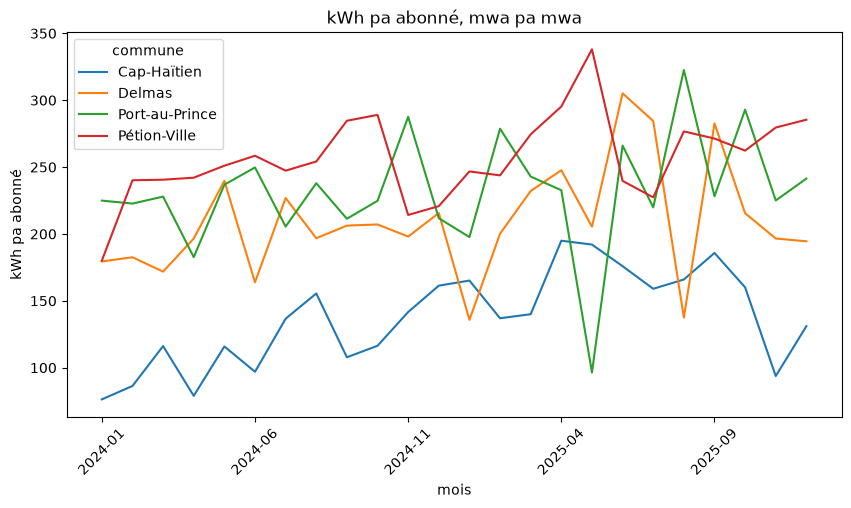

In [13]:
import matplotlib.pyplot as plt

tableau = avec_meteo.pivot_table(
    index="commune", columns="annee", values="kwh", aggfunc="sum"
)
# Pousantaj la kalkile anvan nou awondi
tableau["hausse_pct"] = ((tableau[2025] / tableau[2024] - 1) * 100).round(1)
tableau[[2024, 2025]] = (tableau[[2024, 2025]] / 1_000_000).round(2)
print(tableau.sort_values("hausse_pct", ascending=False))

courbes = avec_meteo.pivot_table(
    index="mois", columns="commune", values="kwh_par_abonne", aggfunc="mean"
)
courbes.plot(figsize=(10, 5), title="kWh pa abonné, mwa pa mwa")
plt.ylabel("kWh pa abonné")
plt.xticks(rotation=45)
plt.show()

**Ce qu'on en conclut :**

Cap-Haïtien connaît la plus forte hausse (+22.5 %, de 4.59 à 5.62 millions de kWh), 
Suivie de Pétion-Ville (+12.6 %). 
Delmas, la commune qui consomme le plus, stagne (+1.1 %).

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

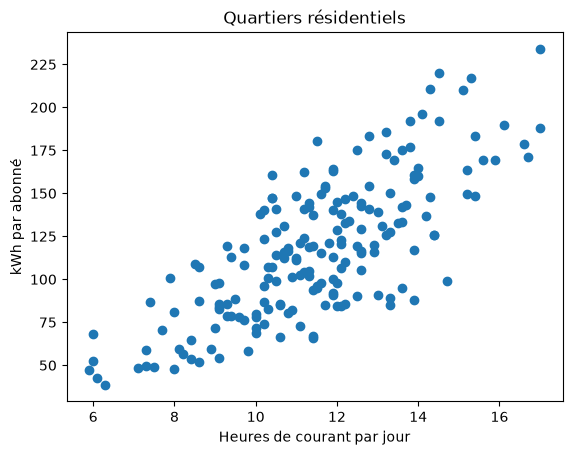

0.76
-0.15


In [14]:
res = avec_meteo[avec_meteo["type"] == "Résidentiel"]

plt.scatter(res["heures_courant"], res["kwh_par_abonne"])
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.title("Quartiers résidentiels")
plt.show()

print(res["kwh_par_abonne"].corr(res["heures_courant"]).round(2))
print(res["kwh_par_abonne"].corr(res["temperature_c"]).round(2))

**Ce qu'on en conclut :**

Dans les quartiers résidentiels, la consommation par abonné suit nettement les heures de courant (corrélation de 0.76) : plus le courant dure, plus on consomme. 
Avec la température, le lien est très faible et négatif (-0.15).

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                 25%   50%    75%
commune                          
Cap-Haïtien      8.3  10.0  11.70
Delmas          10.1  11.9  13.00
Port-au-Prince  10.7  11.6  13.10
Pétion-Ville    10.4  11.6  13.05


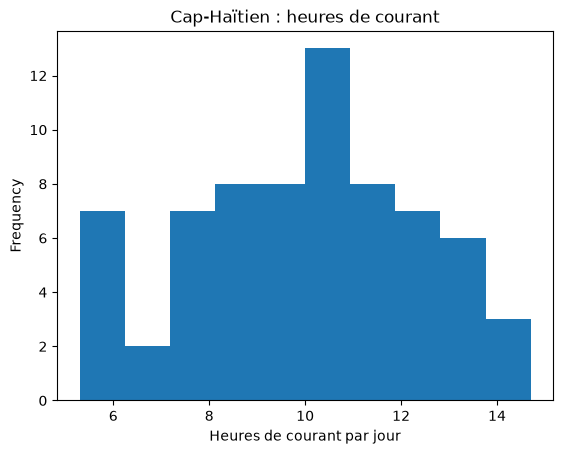

3
        mois   quartier  heures_courant
145  2025-01  Delmas 33             7.4
222  2025-08   Carénage             7.3
265  2025-11     Rue 15             5.9


In [15]:
stats = avec_meteo.groupby("commune")["heures_courant"].describe()[["25%", "50%", "75%"]]
print(stats)

cap = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"]
cap["heures_courant"].plot.hist(bins=10, title="Cap-Haïtien : heures de courant")
plt.xlabel("Heures de courant par jour")
plt.show()

faibles = avec_meteo[(avec_meteo["annee"] == 2025) & (avec_meteo["heures_courant"] < 8)]
print(len(faibles))
print(faibles[["mois", "quartier", "heures_courant"]])

**Ce qu'on en conclut :**

C'est au Cap-Haitien que les coupures sont les plus longues, avec une mediane de 10,0 heures de courant par jour ($Q1 = 8,3$ ; $Q3 = 11,7$), contre 11,6 a 11,9 heures dans les autres communes. En 2025, trois releves sont meme descendus sous le seuil des 8 heures : Delmas 33 (7,4 h), Carenage (7,3 h) et la Rue 15 (5,9 h).

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
print(avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]])

        mois      quartier        type     kwh
213  2025-07     Delmas 33  Commercial  742780
121  2024-11  Centre-ville  Commercial  597730
235  2025-09     Delmas 33  Commercial  591420


**Ce qu'on en conclut :**

Les trois consommations les plus elevees proviennent de quartiers commerciaux : Delmas 33 en juillet 2025 (742 780 kWh), le Centre-ville en novembre 2024 (597 730 kWh) et Delmas 33 en septembre 2025 (591 420 kWh). Ces releves correspondent a des mois caracterises par une forte disponibilite electrique (respectivement 16,9, 17,5 et 14,8 heures par jour), ce qui suggere que la consommation augmente lorsque le courant est disponible.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.